In [1]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

SEED = 42
NUM_FEATURES = 10
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())


Combined shape: (20000, 79)
Columns: Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std'],
      dtype='object') ...
Unique labels: ['BENIGN' 'DoS Hulk' 'PortScan' 'DDoS' 'DoS slowloris' 'DoS GoldenEye'
 'FTP-Patator' 'DoS Slowhttptest' 'Bot' 'SSH-Patator' 'Web Attack � XSS'
 'Web Attack � Brute Force' 'Infiltration']


In [2]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

df['Label'] = df['Label'].apply(lambda x: 0 if x.strip() == "BENIGN" else 1)

print("Unique labels after mapping:", df['Label'].unique())
print(df['Label'].value_counts())

feature_names = df.columns
# Separate features/labels
X = df.drop('Label', axis=1)
y = df['Label']


# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")


X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

Unique labels after mapping: [0 1]
Label
0    16085
1     3893
Name: count, dtype: int64
Original class distribution (train): [12867  3115]
Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'
(15982, 10) (3996, 10)


In [3]:
n_layers = 7

dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifier(nn.Module):
    def __init__(self, n_layers, n_qubits):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, 1)
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # No sigmoid here

<generator object Module.parameters at 0x7fd5fa40fca0>
Epoch 10/100, Loss: 0.2095
Epoch 20/100, Loss: 0.1688
Epoch 30/100, Loss: 0.1470
Epoch 40/100, Loss: 0.1409
Epoch 50/100, Loss: 0.1344
Epoch 60/100, Loss: 0.1228
Epoch 70/100, Loss: 0.1192
Epoch 80/100, Loss: 0.1198
Epoch 90/100, Loss: 0.1154
Epoch 100/100, Loss: 0.1157
QNN Accuracy on Test Data: 0.9370
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.99      0.96       805
           1       0.92      0.74      0.82       195

    accuracy                           0.94      1000
   macro avg       0.93      0.86      0.89      1000
weighted avg       0.94      0.94      0.93      1000



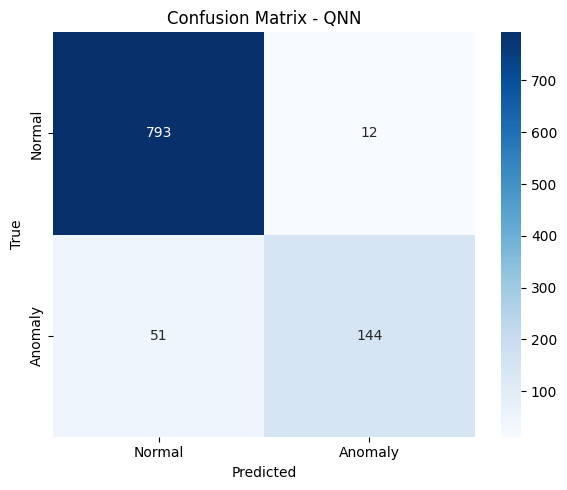

In [5]:
X_train_300 = X_train[:3000]
X_test_100 = X_test[:1000]
y_train_300 = y_train[:3000]
y_test_100 = y_test[:1000]

loss_values = []

# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
print(model.parameters())

# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
# with torch.no_grad():
#     y_pred_logits = model(X_test_tensor)
#     qnn_preds = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

with torch.no_grad():
    y_pred_logits = model(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)


accuracy_qnn = accuracy_score(y_test_100, qnn_preds)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, qnn_preds))

cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [6]:

from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm

# Use your existing trained model and test data
# Assuming you have: model, X_test_tensor, y_test_tensor, NUM_FEATURES, n_layers

# FAST VERSION - Use only 200 test samples for speed
n_test_samples = 200
X_test_fast = X_test_tensor[:n_test_samples]
y_test_fast = y_test_tensor[:n_test_samples]

# Define noise levels to test
noise_levels = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Noise types to analyze
noise_types = ['depolarizing', 'bitflip', 'phaseflip', 'amplitude_damping', 'phase_damping']

results = {noise: [] for noise in noise_types}

print("Starting Fast Noise Robustness Analysis...")
print(f"Testing {len(noise_levels)} noise levels on {n_test_samples} samples")

# Function to create noisy QNN
def create_noisy_qnn(noise_type, noise_prob, n_layers, n_qubits):
    dev = qml.device("default.mixed", wires=n_qubits)
    
    @qml.qnode(dev, interface="torch")
    def noisy_circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits))
        
        for l in range(n_layers):
            for i in range(n_qubits):
                qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
            
            for i in range(n_qubits):
                qml.CNOT(wires=[i, (i + 1) % n_qubits])
            
            # Apply noise after each layer
            for i in range(n_qubits):
                if noise_type == 'depolarizing':
                    qml.DepolarizingChannel(noise_prob, wires=i)
                elif noise_type == 'bitflip':
                    qml.BitFlip(noise_prob, wires=i)
                elif noise_type == 'phaseflip':
                    qml.PhaseFlip(noise_prob, wires=i)
                elif noise_type == 'amplitude_damping':
                    qml.AmplitudeDamping(noise_prob, wires=i)
                elif noise_type == 'phase_damping':
                    qml.PhaseDamping(noise_prob, wires=i)
        
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    
    return noisy_circuit

# Test each noise type
for noise_type in noise_types:
    print(f"\n{'='*50}")
    print(f"Testing {noise_type.upper()} noise")
    print(f"{'='*50}")
    
    for noise_level in tqdm(noise_levels, desc=f"{noise_type}"):
        # Create noisy circuit
        noisy_qnode = create_noisy_qnn(noise_type, noise_level, n_layers, NUM_FEATURES)
        
        # Create new model with noisy circuit
        class NoisyQNNClassifier(nn.Module):
            def __init__(self, qnode, weights, n_qubits):
                super().__init__()
                self.qnode = qnode
                self.weights = weights
                self.fc = nn.Linear(n_qubits, 1)
                # Copy trained weights
                self.fc.weight.data = model.fc.weight.data.clone()
                self.fc.bias.data = model.fc.bias.data.clone()
            
            def forward(self, x):
                batch_size = x.shape[0]
                outputs = []
                for i in range(batch_size):
                    out = self.qnode(x[i], self.weights)
                    outputs.append(out)
                x = torch.stack(outputs)
                x = self.fc(x)
                return x
        
        # Extract weights from trained model
        trained_weights = None
        for name, param in model.named_parameters():
            if 'weight' in name and param.shape == (n_layers, NUM_FEATURES, 3):
                trained_weights = param.data.clone()
                break
        
        noisy_model = NoisyQNNClassifier(noisy_qnode, trained_weights, NUM_FEATURES)
        noisy_model.eval()
        
        # Evaluate
        with torch.no_grad():
            y_pred_logits = noisy_model(X_test_fast)
            predictions = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()
        
        accuracy = accuracy_score(y_test_fast.numpy(), predictions)
        results[noise_type].append(accuracy)
        
        print(f"  Noise={noise_level:.3f}: Accuracy={accuracy:.4f}")

# Plot results
print("\n" + "="*50)
print("GENERATING PLOTS...")
print("="*50)

plt.figure(figsize=(15, 10))

for idx, noise_type in enumerate(noise_types, 1):
    plt.subplot(2, 3, idx)
    plt.plot(noise_levels, results[noise_type], marker='o', linewidth=2, markersize=8)
    plt.xlabel('Noise Level', fontsize=11)
    plt.ylabel('Accuracy', fontsize=11)
    plt.title(f'{noise_type.replace("_", " ").title()} Noise', fontsize=12, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.ylim([0, 1.05])

plt.tight_layout()
plt.savefig('noise_robustness_analysis.png', dpi=300, bbox_inches='tight')
print("Saved plot: noise_robustness_analysis.png")
plt.show()

# Summary comparison plot - styled like the reference figure
plt.figure(figsize=(8, 6))

# Define colors and styles for each noise type
colors = {
    'depolarizing': 'blue',
    'bitflip': 'red',
    'phaseflip': 'green',
    'amplitude_damping': 'orange',
    'phase_damping': 'purple'
}

for noise_type in noise_types:
    plt.plot(noise_levels, results[noise_type], 
             marker='o', 
             label=noise_type.replace('_', ' '),
             color=colors[noise_type],
             linewidth=2,
             markersize=6)

plt.xlabel('Noise probability [p]', fontsize=11)
plt.ylabel('F1 Score', fontsize=11)
plt.title('Figure 9: Noise Robustness Analysis', fontsize=12, fontweight='bold')
plt.legend(loc='right', fontsize=9)
plt.grid(True, alpha=0.2, linestyle='-', linewidth=0.5)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.tight_layout()
plt.savefig('noise_comparison.png', dpi=300, bbox_inches='tight')
print("Saved plot: noise_comparison.png")
plt.show()

# Print summary table
print("\n" + "="*50)
print("SUMMARY TABLE")
print("="*50)
df_results = pd.DataFrame(results, index=[f"{x:.3f}" for x in noise_levels])
df_results.index.name = 'Noise Level'
print(df_results.round(4))
df_results.to_csv('noise_results.csv')
print("\nSaved results: noise_results.csv")

print("\n" + "="*50)
print("ANALYSIS COMPLETE!")
print(f"Time estimate: ~15-30 minutes")
print("="*50)

Starting Fast Noise Robustness Analysis...
Testing 6 noise levels on 200 samples

Testing DEPOLARIZING noise


depolarizing:   0%|          | 0/6 [04:46<?, ?it/s]


TypeError: expected Tensor as element 0 in argument 0, but got list